
# DBSCAN on Non-Spherical Data: The Two Moons Dataset




## What we will learn

By the end of this demonstration, you will be able to explain:

- Why K-Means struggles with non-spherical clusters
- Why DBSCAN can discover clusters of arbitrary shape
- What `eps` means
- What `min_samples` means
- What a core point, border point, and noise point are
- Why parameter tuning matters
- How to use a k-distance plot as a guide for choosing `eps`
- How DBSCAN identifies noise/outliers


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")



## 1. Create the Two Moons dataset

We create **500 observations** with a small amount of noise.

The important point is that the clusters are **not circles or blobs**. They are two curved, interleaving shapes.

This is exactly the type of non-flat geometry for which DBSCAN can be useful.


In [ ]:

X, y_true = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

print("Number of observations:", X.shape[0])
print("Number of features:", X.shape[1])


Number of observations: 500
Number of features: 2


In [ ]:

data = pd.DataFrame(
    X,
    columns=["Feature_1", "Feature_2"]
)

data.head()


,Feature_1,Feature_2
0,0.830640,-0.425055
1,0.759684,0.829335
2,1.039113,-0.488126
3,-0.281591,0.969380
4,0.315699,1.111454



## 2. Visualize the raw data

Before applying any algorithm, let's simply look at the data.

Can you see the two curved clusters?


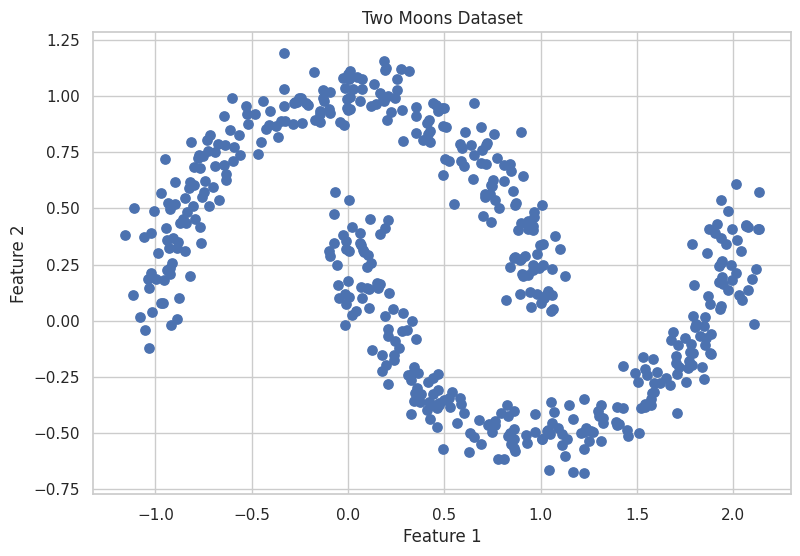

In [ ]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=45
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two Moons Dataset")
plt.show()



## 3. Why K-Means is not ideal here

K-Means works by assigning observations to the nearest centroid.

That creates a problem here: our clusters are curved.

Let's deliberately run K-Means with `k = 2` so we can visually compare its result with DBSCAN later.

> We are using `k = 2` only because we know the dataset was generated with two groups. This is a demonstration of the algorithm, not information DBSCAN receives.


In [ ]:

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)


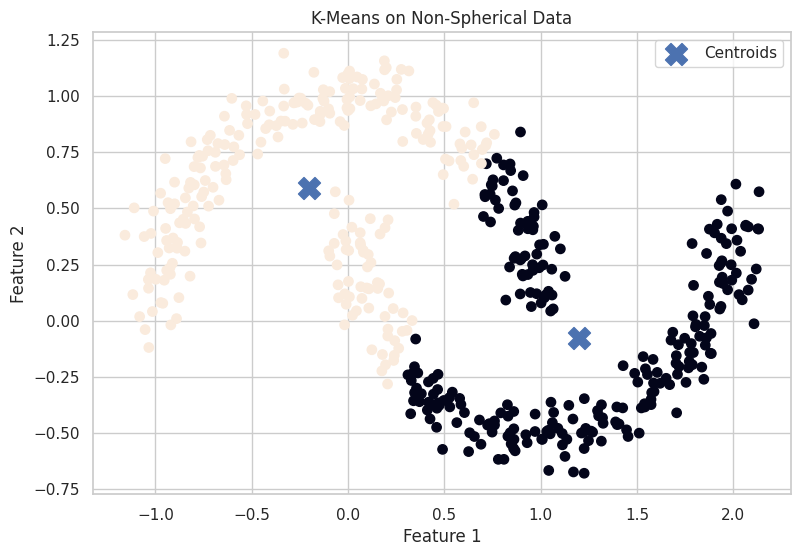

In [ ]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels,
    s=45
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means on Non-Spherical Data")
plt.legend()
plt.show()



### What should we notice?

K-Means has to create partitions around centroids.

But the actual groups are curved.

This gives us a natural motivation for DBSCAN:

**Instead of asking "Which centroid is this point closest to?", DBSCAN asks "Is this point located in a sufficiently dense neighborhood?"**



# 4. Apply DBSCAN

DBSCAN stands for:

**Density-Based Spatial Clustering of Applications with Noise**

It groups points based on local density.

The two parameters we need to understand first are:

### `eps`
The neighborhood radius around a point.

### `min_samples`
The minimum number of samples required in that neighborhood for a point to qualify as a core point.

The scikit-learn implementation defines `eps` as the maximum distance between two samples for one to be considered a neighbor of the other. `min_samples` controls how many samples are needed for a point to be considered a core point.


In [ ]:

dbscan = DBSCAN(
    eps=0.20,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X)

dbscan_labels[:20]


array([0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0])


# 5. Visualize the DBSCAN result

This is the key moment of the demonstration.

Unlike K-Means, DBSCAN can follow the curved density structure of the moons.

We also highlight noise points separately.


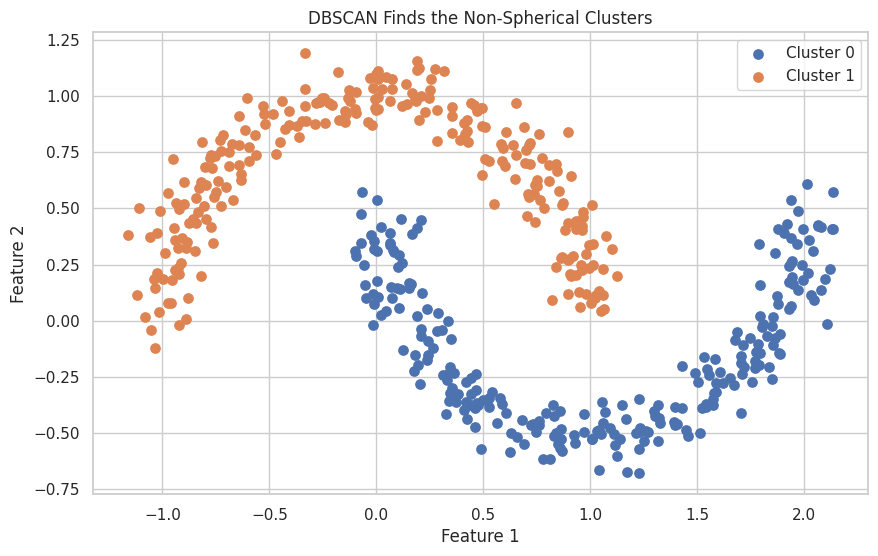

In [ ]:

plt.figure(figsize=(10, 6))

for label in sorted(set(dbscan_labels)):

    mask = dbscan_labels == label

    if label == -1:
        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            marker="x",
            s=90,
            label="Noise"
        )
    else:
        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            s=45,
            label=f"Cluster {label}"
        )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN Finds the Non-Spherical Clusters")
plt.legend()
plt.show()



## 6. What happens when `eps` changes?

This is one of the most important DBSCAN experiments.

We will keep:

`min_samples = 5`

and change only `eps`.

A very small `eps` may classify many points as noise.

A very large `eps` can cause separate density regions to merge.


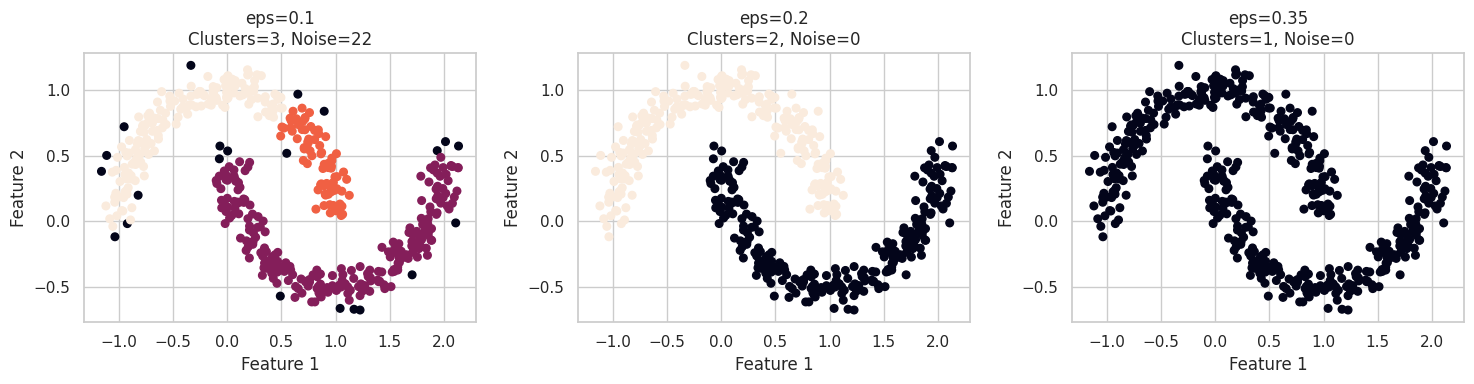

In [ ]:

eps_values = [0.10, 0.20, 0.35]

plt.figure(figsize=(15, 4))

for plot_number, eps in enumerate(eps_values, 1):

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X)

    ax = plt.subplot(1, 3, plot_number)

    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        s=30
    )

    clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = np.sum(labels == -1)

    ax.set_title(
        f"eps={eps}\nClusters={clusters}, Noise={noise}"
    )

    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()



# 7. What happens when `min_samples` changes?

Now keep:

`eps = 0.20`

and vary `min_samples`.

Increasing `min_samples` makes DBSCAN require a denser neighborhood before declaring a point to be a core point.


In [ ]:

min_samples_values = [3, 5, 8, 12, 20]

results = []

for min_samples in min_samples_values:

    model = DBSCAN(
        eps=0.20,
        min_samples=min_samples
    )

    labels = model.fit_predict(X)

    clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = np.sum(labels == -1)

    results.append({
        "min_samples": min_samples,
        "clusters": clusters,
        "noise_points": noise,
        "noise_percentage": round(noise / len(X) * 100, 2)
    })

pd.DataFrame(results)


,min_samples,clusters,noise_points,noise_percentage
0,3,2,0,0.0
1,5,2,0,0.0
2,8,2,0,0.0
3,12,2,0,0.0
4,20,2,3,0.6



# 8. Choosing `eps` with a k-distance plot

Instead of simply guessing `eps`, we can inspect distances to the kth nearest neighbor.

Here we use:

`k = min_samples`

The sharp upward bend in the sorted distance curve can provide a useful starting point for selecting `eps`.

It is a **guide**, not a magic automatic answer.


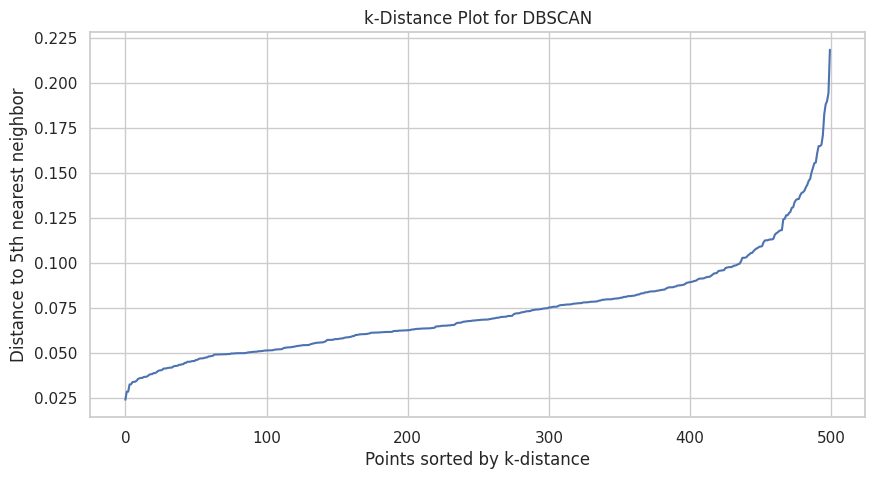

In [ ]:

min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X)

distances, indices = neighbors.kneighbors(X)

k_distances = np.sort(
    distances[:, -1]
)

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Points sorted by k-distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("k-Distance Plot for DBSCAN")
plt.show()



# 9. Identify core, border, and noise points

DBSCAN classifies observations according to density.

### Core point
Has enough neighbors within `eps`.

### Border point
Is close enough to a core point to become part of a cluster, but does not itself satisfy the core-density requirement.

### Noise point
Does not belong to any sufficiently dense cluster.


In [ ]:

final_model = DBSCAN(
    eps=0.20,
    min_samples=5
)

final_model.fit(X)

labels = final_model.labels_
core_indices = final_model.core_sample_indices_

is_core = np.zeros(len(X), dtype=bool)
is_core[core_indices] = True

is_noise = labels == -1
is_border = (~is_core) & (~is_noise)

print("Core points:", is_core.sum())
print("Border points:", is_border.sum())
print("Noise points:", is_noise.sum())


Core points: 499
Border points: 1
Noise points: 0


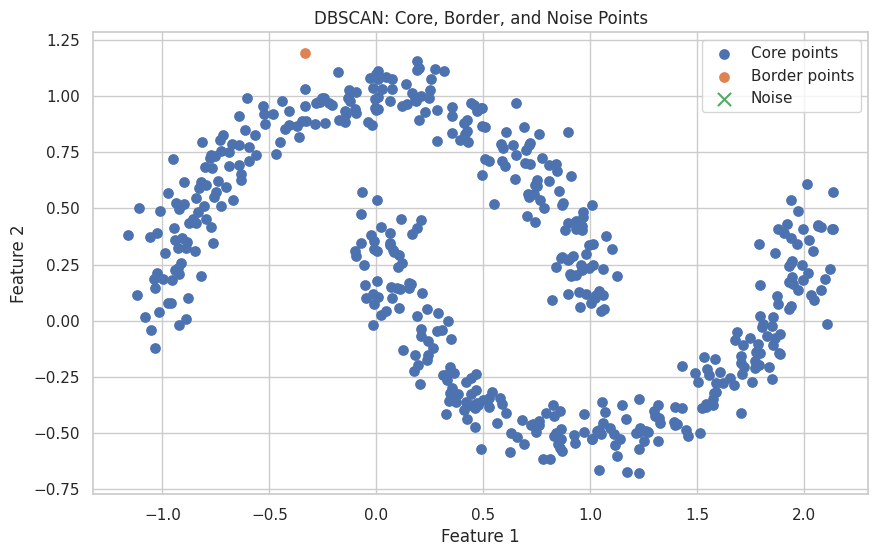

In [ ]:

plt.figure(figsize=(10, 6))

plt.scatter(
    X[is_core, 0],
    X[is_core, 1],
    s=45,
    label="Core points"
)

plt.scatter(
    X[is_border, 0],
    X[is_border, 1],
    s=45,
    marker="o",
    label="Border points"
)

plt.scatter(
    X[is_noise, 0],
    X[is_noise, 1],
    s=90,
    marker="x",
    label="Noise"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN: Core, Border, and Noise Points")
plt.legend()
plt.show()



# 10. Optional evaluation

For this demonstration we know the generated dataset has two underlying groups (`y_true`).

However, DBSCAN itself does **not** use these labels.

We can calculate a silhouette score for the DBSCAN assignments, excluding noise.

Remember: clustering metrics are diagnostics; they do not replace understanding the data and the clustering objective.


In [ ]:

cluster_mask = labels != -1

if len(set(labels[cluster_mask])) >= 2:

    score = silhouette_score(
        X[cluster_mask],
        labels[cluster_mask]
    )

    print("Silhouette Score:", round(score, 3))

else:
    print("Silhouette Score cannot be calculated.")


Silhouette Score: 0.331



# 11. Final comparison: K-Means vs DBSCAN

The most important visual message of this tutorial is:

### K-Means
- Requires the number of clusters
- Uses centroids
- Works naturally with compact/roughly spherical groups
- Struggles with these curved moons

### DBSCAN
- Does not require the number of clusters in advance
- Uses density
- Can identify non-spherical cluster shapes
- Can identify noise points
- Requires careful selection of `eps` and `min_samples`


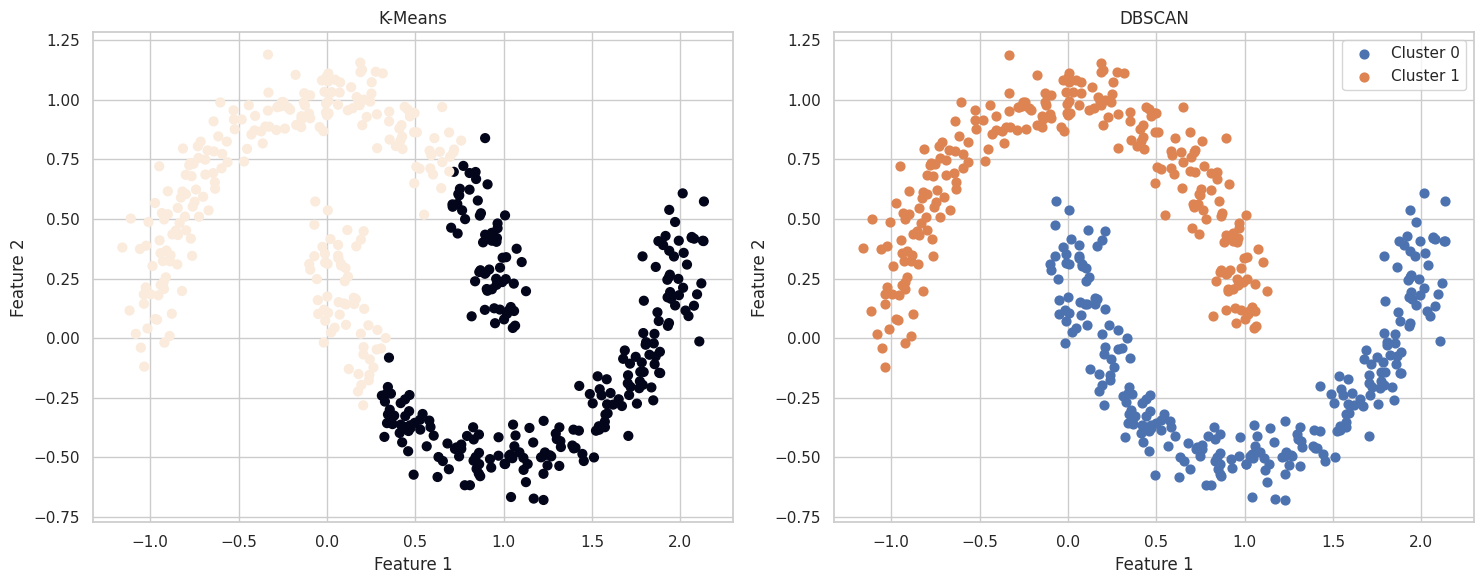

In [ ]:

final_dbscan = DBSCAN(
    eps=0.20,
    min_samples=5
)

final_dbscan_labels = final_dbscan.fit_predict(X)

plt.figure(figsize=(15, 6))

# K-Means
plt.subplot(1, 2, 1)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels,
    s=40
)

plt.title("K-Means")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# DBSCAN
plt.subplot(1, 2, 2)

for label in sorted(set(final_dbscan_labels)):

    mask = final_dbscan_labels == label

    if label == -1:
        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            marker="x",
            s=80,
            label="Noise"
        )
    else:
        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            s=40,
            label=f"Cluster {label}"
        )

plt.title("DBSCAN")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.tight_layout()
plt.show()



# 12. Final Takeaways

### The big lesson

> **DBSCAN is powerful because it follows density, not geometric assumptions about cluster shape.**

For our two-moons example:

- The clusters are curved and non-spherical.
- K-Means has difficulty following their shape.
- DBSCAN can discover the two dense curved regions.
- `eps` controls the neighborhood radius.
- `min_samples` controls the density requirement.
- `-1` represents noise.
- Scaling is important when features have different numerical ranges.
- Parameter selection should be based on the dataset's density structure.

### A good closing line for the video

**"If your clusters look nothing like neat circles, don't force K-Means to solve the problem. Sometimes the structure of the data is telling you that density-based clustering is the better tool."**
